In [6]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../data/raw/cmapss")

train_path = DATA_DIR / "train_FD001.txt"

train = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None
)

print("Dataset shape:", train.shape)
print(train.head())

Dataset shape: (20631, 26)
   0   1       2       3      4       5       6        7        8      9   \
0   1   1 -0.0007 -0.0004  100.0  518.67  641.82  1589.70  1400.60  14.62   
1   1   2  0.0019 -0.0003  100.0  518.67  642.15  1591.82  1403.14  14.62   
2   1   3 -0.0043  0.0003  100.0  518.67  642.35  1587.99  1404.20  14.62   
3   1   4  0.0007  0.0000  100.0  518.67  642.35  1582.79  1401.87  14.62   
4   1   5 -0.0019 -0.0002  100.0  518.67  642.37  1582.85  1406.22  14.62   

   ...      16       17       18      19    20   21    22     23     24  \
0  ...  521.66  2388.02  8138.62  8.4195  0.03  392  2388  100.0  39.06   
1  ...  522.28  2388.07  8131.49  8.4318  0.03  392  2388  100.0  39.00   
2  ...  522.42  2388.03  8133.23  8.4178  0.03  390  2388  100.0  38.95   
3  ...  522.86  2388.08  8133.83  8.3682  0.03  392  2388  100.0  38.88   
4  ...  522.19  2388.04  8133.80  8.4294  0.03  393  2388  100.0  38.90   

        25  
0  23.4190  
1  23.4236  
2  23.3442  
3  23.3

In [7]:
# Define names for all 26 columns

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Assign the column names
train.columns = columns

# Display the first five rows
print(train.head())

   engine_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0          1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1          1      2     0.0019    -0.0003      100.0    518.67    642.15   
2          1      3    -0.0043     0.0003      100.0    518.67    642.35   
3          1      4     0.0007     0.0000      100.0    518.67    642.35   
4          1      5    -0.0019    -0.0002      100.0    518.67    642.37   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   
3   1582.79   1401.87     14.62  ...     522.86    2388.08    8133.83   
4   1582.85   1406.22     14.62  ...     522.19    2388.04    8133.80   

   sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21  
0     8.4195       0.03

In [8]:
# How many different engines are in the dataset?
print("Number of engines:", train["engine_id"].nunique())

# How many operating cycles does each engine have?
engine_cycles = train.groupby("engine_id")["cycle"].max()

print("\nFirst 10 engines and their final recorded cycles:")
print(engine_cycles.head(10))

# Basic statistics for cycle counts
print("\nCycle statistics:")
print(engine_cycles.describe())

Number of engines: 100

First 10 engines and their final recorded cycles:
engine_id
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: cycle, dtype: int64

Cycle statistics:
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


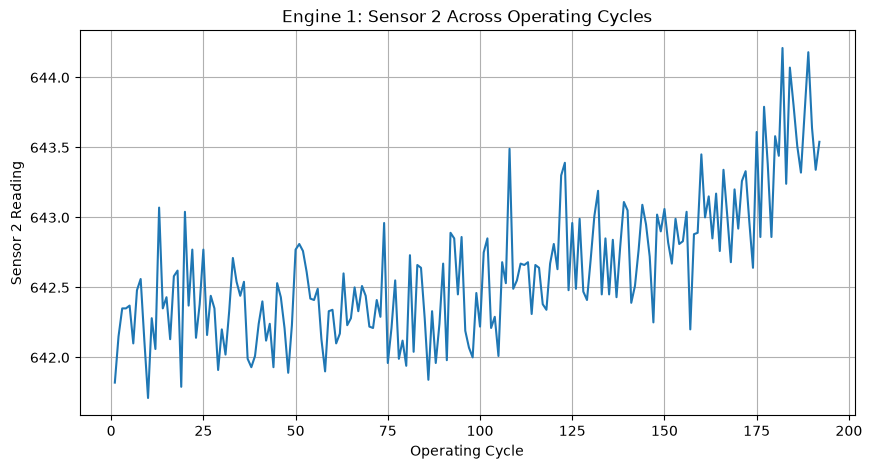

In [9]:
import matplotlib.pyplot as plt

# Select the observations for Engine 1
engine_1 = train[train["engine_id"] == 1]

# Plot Sensor 2 across operating cycles
plt.figure(figsize=(10, 5))
plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2"]
)

plt.title("Engine 1: Sensor 2 Across Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 2 Reading")
plt.grid(True)
plt.show()

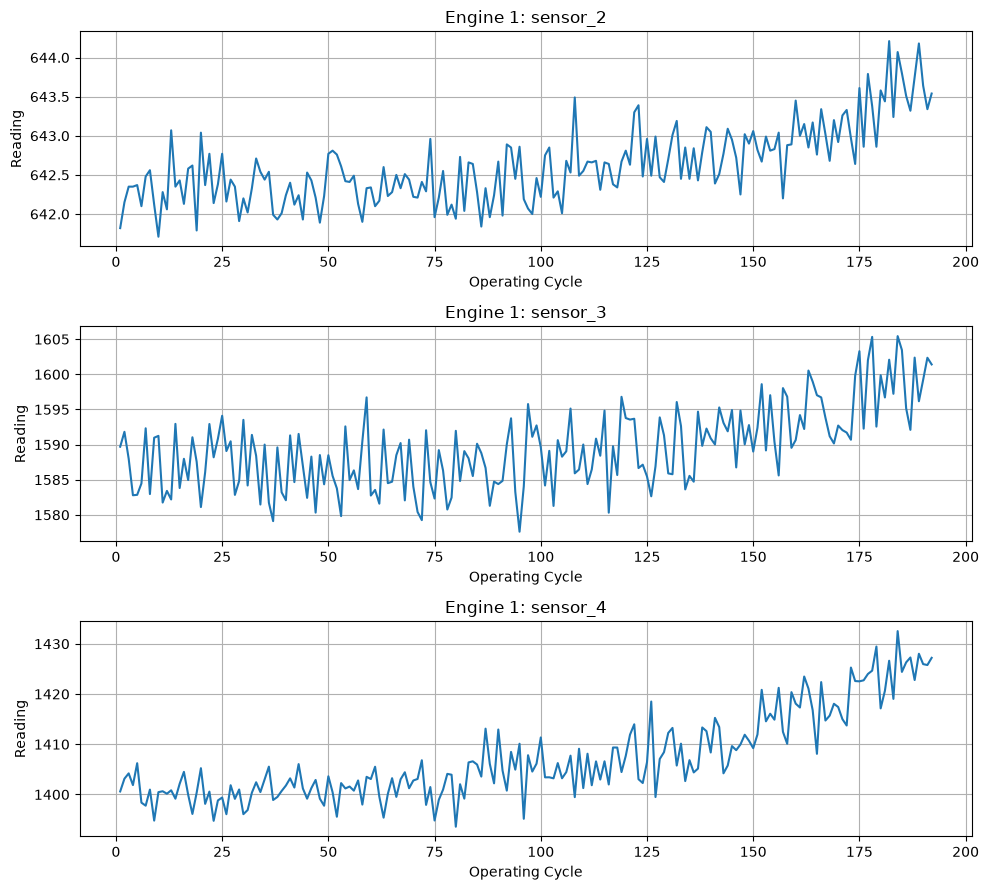

In [10]:
sensors = ["sensor_2", "sensor_3", "sensor_4"]

fig, axes = plt.subplots(3, 1, figsize=(10, 9))

for ax, sensor in zip(axes, sensors):
    ax.plot(engine_1["cycle"], engine_1[sensor])
    ax.set_title(f"Engine 1: {sensor}")
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Reading")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [11]:
# Find the final recorded cycle for each engine
final_cycles = train.groupby("engine_id")["cycle"].max()

# Map each engine's final cycle onto every row
train["final_cycle"] = train["engine_id"].map(final_cycles)

# Calculate remaining useful life
train["RUL"] = train["final_cycle"] - train["cycle"]

# Inspect the result for Engine 1
print(
    train[train["engine_id"] == 1][
        ["engine_id", "cycle", "final_cycle", "RUL"]
    ].head()
)

print("\nLast five cycles of Engine 1:")
print(
    train[train["engine_id"] == 1][
        ["engine_id", "cycle", "final_cycle", "RUL"]
    ].tail()
)

   engine_id  cycle  final_cycle  RUL
0          1      1          192  191
1          1      2          192  190
2          1      3          192  189
3          1      4          192  188
4          1      5          192  187

Last five cycles of Engine 1:
     engine_id  cycle  final_cycle  RUL
187          1    188          192    4
188          1    189          192    3
189          1    190          192    2
190          1    191          192    1
191          1    192          192    0


In [12]:
print("RUL statistics:")
print(train["RUL"].describe())

print("\nRUL distribution summary:")
print("Minimum RUL:", train["RUL"].min())
print("Maximum RUL:", train["RUL"].max())
print("Average RUL:", train["RUL"].mean())

RUL statistics:
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

RUL distribution summary:
Minimum RUL: 0
Maximum RUL: 361
Average RUL: 107.80786195530997


In [13]:
# Check for missing values
print("Missing values per column:")
print(train.isnull().sum().sum())

# Check for duplicate rows
print("\nDuplicate rows:", train.duplicated().sum())

# Find sensors that have no variation
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

sensor_std = train[sensor_columns].std()

print("\nSensors with zero variation:")
print(sensor_std[sensor_std == 0])


Missing values per column:
0

Duplicate rows: 0

Sensors with zero variation:
sensor_1     0.0
sensor_10    0.0
sensor_18    0.0
sensor_19    0.0
dtype: float64


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../data/raw/cmapss")

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train = pd.read_csv(
    DATA_DIR / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

test = pd.read_csv(
    DATA_DIR / "test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

rul_test = pd.read_csv(
    DATA_DIR / "RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Test RUL shape:", rul_test.shape)

print("\nTraining preview:")
print(train.head())

Training shape: (20631, 26)
Test shape: (13096, 26)
Test RUL shape: (100, 1)

Training preview:
   engine_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0          1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1          1      2     0.0019    -0.0003      100.0    518.67    642.15   
2          1      3    -0.0043     0.0003      100.0    518.67    642.35   
3          1      4     0.0007     0.0000      100.0    518.67    642.35   
4          1      5    -0.0019    -0.0002      100.0    518.67    642.37   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   
3   1582.79   1401.87     14.62  ...     522.86    2388.08    8133.83   
4   1582.85   1406.22     14.62  ...     522.19    2388.04    8133.80   

   senso

In [15]:
final_cycles = train.groupby("engine_id")["cycle"].max()

train["final_cycle"] = train["engine_id"].map(final_cycles)

train["RUL"] = train["final_cycle"] - train["cycle"]

print(train[["engine_id", "cycle", "final_cycle", "RUL"]].head())
print("\nRUL summary:")
print(train["RUL"].describe())

   engine_id  cycle  final_cycle  RUL
0          1      1          192  191
1          1      2          192  190
2          1      3          192  189
3          1      4          192  188
4          1      5          192  187

RUL summary:
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64


In [16]:
print("Missing values:", train.isnull().sum().sum())
print("Duplicate rows:", train.duplicated().sum())

feature_columns = [
    "setting_1", "setting_2", "setting_3"
] + [f"sensor_{i}" for i in range(1, 22)]

feature_std = train[feature_columns].std()

constant_features = feature_std[feature_std == 0].index.tolist()

print("\nConstant features:")
print(constant_features)

print("\nNumber of engines:", train["engine_id"].nunique())
print("Number of observations:", len(train))

Missing values: 0
Duplicate rows: 0

Constant features:
['setting_3', 'sensor_1', 'sensor_10', 'sensor_18', 'sensor_19']

Number of engines: 100
Number of observations: 20631


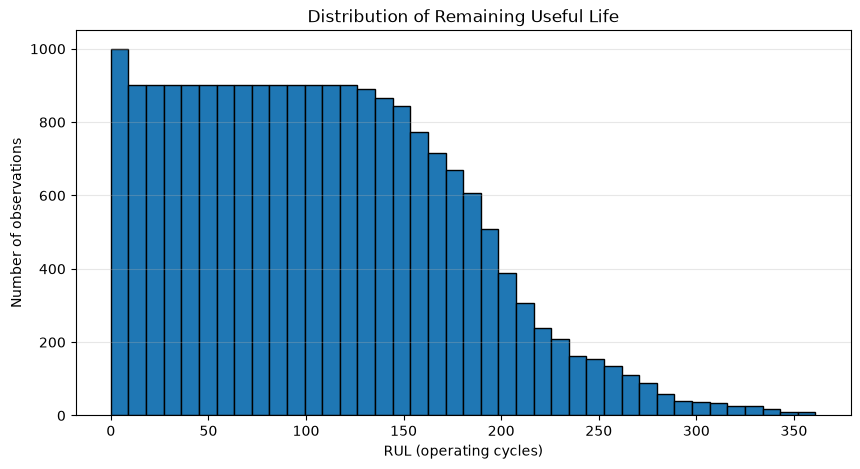

In [17]:
plt.figure(figsize=(10, 5))

plt.hist(train["RUL"], bins=40, edgecolor="black")

plt.title("Distribution of Remaining Useful Life")
plt.xlabel("RUL (operating cycles)")
plt.ylabel("Number of observations")
plt.grid(axis="y", alpha=0.3)

plt.show()

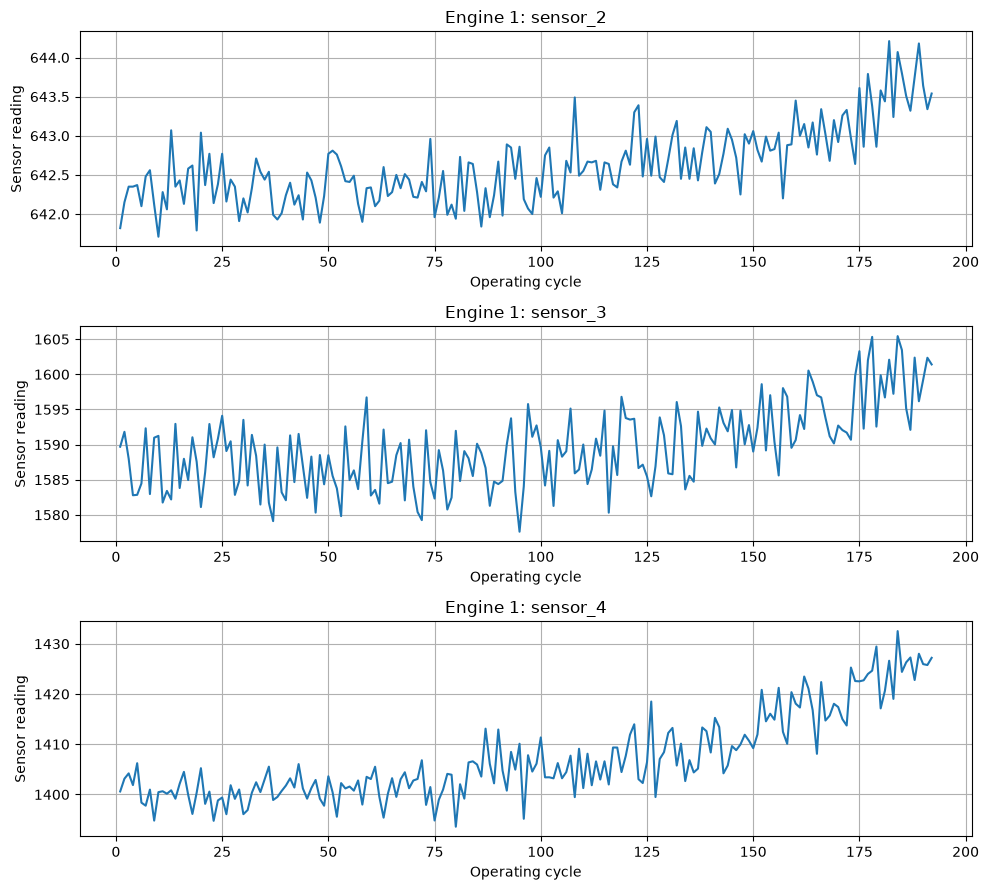

In [18]:
engine_id = 1
engine_data = train[train["engine_id"] == engine_id]

sensors_to_plot = ["sensor_2", "sensor_3", "sensor_4"]

fig, axes = plt.subplots(3, 1, figsize=(10, 9))

for ax, sensor in zip(axes, sensors_to_plot):
    ax.plot(engine_data["cycle"], engine_data[sensor])
    ax.set_title(f"Engine {engine_id}: {sensor}")
    ax.set_xlabel("Operating cycle")
    ax.set_ylabel("Sensor reading")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [19]:
feature_columns = [
    "setting_1", "setting_2", "setting_3"
] + [f"sensor_{i}" for i in range(1, 22)]

constant_features = [
    col for col in feature_columns
    if train[col].nunique() <= 1
]

model_features = [
    col for col in feature_columns
    if col not in constant_features
]

print("Removed constant features:", constant_features)
print("Features retained:", len(model_features))
print(model_features)

Removed constant features: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Features retained: 17
['setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [20]:
test_final_cycles = test.groupby("engine_id")["cycle"].max()

print("Test engines:", test["engine_id"].nunique())
print("\nFinal observed cycles for first 10 test engines:")
print(test_final_cycles.head(10))

print("\nOfficial test RUL values:")
print(rul_test.head(10))

assert test["engine_id"].nunique() == len(rul_test), (
    "Test engine count does not match the number of RUL labels."
)

Test engines: 100

Final observed cycles for first 10 test engines:
engine_id
1      31
2      49
3     126
4     106
5      98
6     105
7     160
8     166
9      55
10    192
Name: cycle, dtype: int64

Official test RUL values:
   RUL
0  112
1   98
2   69
3   82
4   91
5   93
6   91
7   95
8  111
9   96


In [21]:
RUL_CAP = 125

train["RUL_capped"] = train["RUL"].clip(upper=RUL_CAP)

print(
    train[["RUL", "RUL_capped"]].describe()
)

                RUL    RUL_capped
count  20631.000000  20631.000000
mean     107.807862     86.829286
std       68.880990     41.673699
min        0.000000      0.000000
25%       51.000000     51.000000
50%      103.000000    103.000000
75%      155.000000    125.000000
max      361.000000    125.000000


In [22]:
# Select the input features
feature_columns = (
    [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Remove sensors that never change
constant_features = [
    col for col in feature_columns
    if train[col].std() == 0
]

feature_columns = [
    col for col in feature_columns
    if col not in constant_features
]

# Define inputs (X) and target (y)
X = train[feature_columns]
y = train["RUL_capped"]  # Use capped RUL for this experiment

print("Number of input features:", len(feature_columns))
print("Removed constant features:", constant_features)
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Number of input features: 19
Removed constant features: ['setting_3', 'sensor_1', 'sensor_10', 'sensor_18', 'sensor_19']
Input shape: (20631, 19)
Target shape: (20631,)


In [23]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=train["engine_id"])
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_val.shape[0])

print("Training engines:", train["engine_id"].iloc[train_idx].nunique())
print("Validation engines:", train["engine_id"].iloc[val_idx].nunique())

print(
    "Engines overlap:",
    set(train["engine_id"].iloc[train_idx])
    & set(train["engine_id"].iloc[val_idx])
)

Training rows: 16561
Validation rows: 4070
Training engines: 80
Validation engines: 20
Engines overlap: set()


In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict RUL for unseen validation engines
y_pred = model.predict(X_val)

# RUL cannot be negative
y_pred = np.maximum(y_pred, 0)

# Evaluate the model
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print("Linear Regression Baseline")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

from sklearn.metrics import r2_score

print("R² Score:", round(r2_score(y_val, y_pred), 4))

Linear Regression Baseline
MAE: 16.19
RMSE: 20.21
R² Score: 0.7653


In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_val)
rf_pred = np.maximum(rf_pred, 0)

rf_mae = mean_absolute_error(y_val, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_pred))

print("Random Forest Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
from sklearn.metrics import r2_score

print("Linear Regression R²:", round(r2_score(y_val, y_pred), 4))
print("Random Forest R²:", round(r2_score(y_val, rf_pred), 4))

Random Forest Results
MAE: 12.35
RMSE: 17.07
Linear Regression R²: 0.7653
Random Forest R²: 0.8325


In [29]:
%pip install xgboost

In [30]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_pred = np.maximum(xgb_model.predict(X_val), 0)

print("XGBoost Results")
print("MAE:", round(mean_absolute_error(y_val, xgb_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, xgb_pred)), 2))
print("R²:", round(r2_score(y_val, xgb_pred), 4))

XGBoost Results
MAE: 12.16
RMSE: 16.86
R²: 0.8366


In [31]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "XGBoost"],
    "MAE": [mae, rf_mae, mean_absolute_error(y_val, xgb_pred)],
    "RMSE": [
        rmse,
        rf_rmse,
        np.sqrt(mean_squared_error(y_val, xgb_pred))
    ],
    "R2": [
        r2_score(y_val, y_pred),
        r2_score(y_val, rf_pred),
        r2_score(y_val, xgb_pred)
    ]
})

display(results.round(4))

,Model,MAE,RMSE,R2
0,Linear Regression,16.1850,20.2074,0.7653
1,Random Forest,12.3525,17.0716,0.8325
2,XGBoost,12.1622,16.8610,0.8366


In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluate the current predictions against original, uncapped RUL
y_val_original = train["RUL"].iloc[val_idx]

models_predictions = {
    "Linear Regression": y_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}

original_results = []

for name, predictions in models_predictions.items():
    original_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val_original, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val_original, predictions)),
        "R2": r2_score(y_val_original, predictions)
    })

original_results = pd.DataFrame(original_results)
display(original_results.round(4))

,Model,MAE,RMSE,R2
0,Linear Regression,33.3017,46.1758,0.5053
1,Random Forest,31.5390,45.4343,0.5211
2,XGBoost,31.3131,45.2277,0.5254


In [33]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Use original RUL as the target
y_original = train["RUL"]

y_train_original = y_original.iloc[train_idx]
y_val_original = y_original.iloc[val_idx]

# Train Random Forest on uncapped RUL
rf_original = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf_original.fit(X_train, y_train_original)
rf_original_pred = np.maximum(rf_original.predict(X_val), 0)

# Train XGBoost on uncapped RUL
xgb_original = XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)
xgb_original.fit(X_train, y_train_original)
xgb_original_pred = np.maximum(xgb_original.predict(X_val), 0)

# Compare results against the original RUL
comparison = []

for name, pred in [
    ("Random Forest - Uncapped", rf_original_pred),
    ("XGBoost - Uncapped", xgb_original_pred)
]:
    comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val_original, pred),
        "RMSE": np.sqrt(mean_squared_error(y_val_original, pred)),
        "R2": r2_score(y_val_original, pred)
    })

display(pd.DataFrame(comparison).round(4))

,Model,MAE,RMSE,R2
0,Random Forest - Uncapped,25.8938,35.3942,0.7094
1,XGBoost - Uncapped,25.7025,35.2529,0.7117


In [34]:
# Check the ranges of our input features
feature_summary = X_train.describe().T[
    ["mean", "std", "min", "max"]
]

display(feature_summary.round(3))

,mean,std,min,max
setting_1,-0.000,0.002,-0.009,0.009
setting_2,0.000,0.000,-0.001,0.001
sensor_2,642.678,0.498,641.210,644.530
sensor_3,1590.489,6.085,1571.040,1616.910
sensor_4,1408.879,8.966,1385.190,1441.490
sensor_5,14.620,0.000,14.620,14.620
sensor_6,21.610,0.001,21.600,21.610
sensor_7,553.373,0.878,549.850,556.060
sensor_8,2388.096,0.071,2387.900,2388.560
sensor_9,9065.399,22.660,9021.730,9244.590


In [35]:
# Check correlation between each feature and original RUL
correlations = train[feature_columns].corrwith(train["RUL"])

correlation_table = (
    correlations
    .sort_values(key=abs, ascending=False)
    .to_frame(name="Correlation with RUL")
)

display(correlation_table.round(3))

,Correlation with RUL
sensor_11,-0.696
sensor_4,-0.679
sensor_12,0.672
sensor_7,0.657
sensor_15,-0.643
sensor_21,0.636
sensor_20,0.629
sensor_2,-0.606
sensor_17,-0.606
sensor_3,-0.585


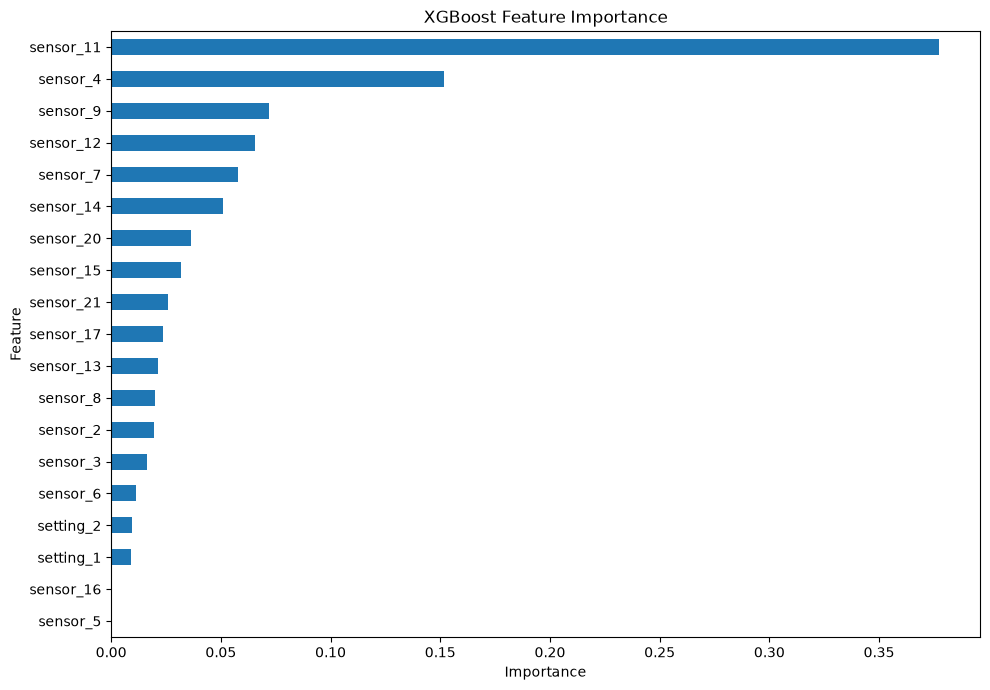

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    xgb_original.feature_importances_,
    index=feature_columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 7))
importance.plot(kind="barh")
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [37]:
%pip install shap

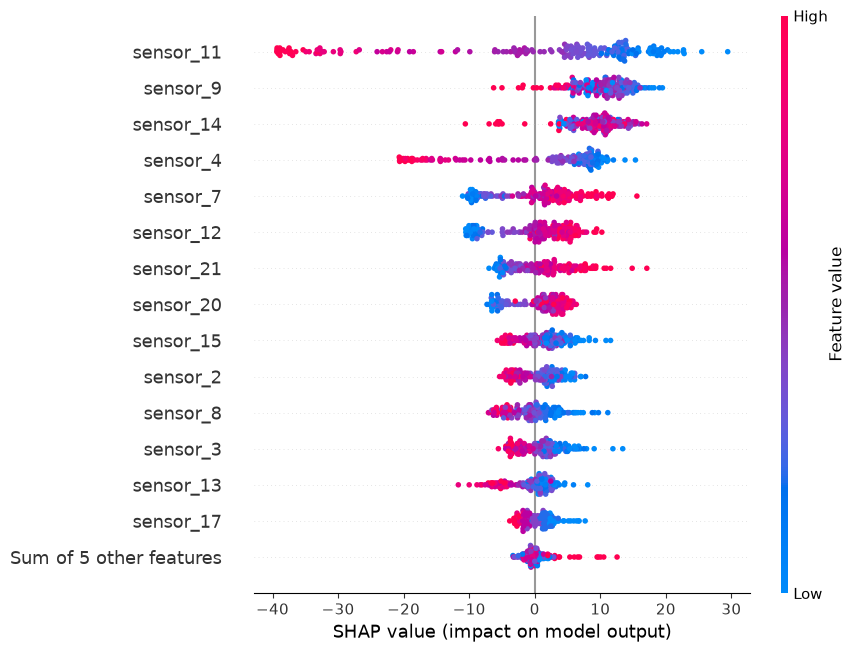

In [38]:
import shap

explainer = shap.TreeExplainer(xgb_original)

# Explain a small sample to keep computation manageable
X_sample = X_val.iloc[:200]
shap_values = explainer(X_sample)

shap.plots.beeswarm(shap_values, max_display=15)

In [39]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Use original RUL for training and validation
y_train_full = train["RUL"].iloc[train_idx]
y_val_full = train["RUL"].iloc[val_idx]

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train_full)
    predictions = np.maximum(model.predict(X_val), 0)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val_full, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val_full, predictions)),
        "R2": r2_score(y_val_full, predictions)
    })

final_comparison = pd.DataFrame(results)
display(final_comparison.round(4))


,Model,MAE,RMSE,R2
0,Linear Regression,29.1429,37.5478,0.6729
1,Random Forest,25.8938,35.3942,0.7094
2,XGBoost,25.7025,35.2529,0.7117


In [40]:
%pip install torch

In [41]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
CUDA available: False


In [42]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
CUDA available: False


In [43]:
from sklearn.preprocessing import StandardScaler

# Create a scaler
scaler = StandardScaler()

# Fit only on training engines, then transform both sets
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Training data shape:", X_train_scaled.shape)
print("Validation data shape:", X_val_scaled.shape)
print("Scaling complete!")

Training data shape: (16561, 19)
Validation data shape: (4070, 19)
Scaling complete!


In [45]:
import numpy as np

SEQUENCE_LENGTH = 30

def create_sequences(X, y, engine_ids, cycles, sequence_length=30):
    X_sequences = []
    y_targets = []

    # Process each engine separately
    for engine_id in np.unique(engine_ids):
        mask = engine_ids == engine_id

        # Keep each engine's rows in cycle order
        engine_X = X[mask]
        engine_y = np.asarray(y)[mask]
        engine_cycles = np.asarray(cycles)[mask]

        order = np.argsort(engine_cycles)
        engine_X = engine_X[order]
        engine_y = engine_y[order]

        # Create rolling windows of consecutive cycles
        for end in range(sequence_length, len(engine_X) + 1):
            X_sequences.append(engine_X[end-sequence_length:end])
            y_targets.append(engine_y[end-1])

    return np.asarray(X_sequences), np.asarray(y_targets)

# Identify the training and validation rows
train_engines = train["engine_id"].iloc[train_idx].to_numpy()
train_cycles = train["cycle"].iloc[train_idx].to_numpy()

val_engines = train["engine_id"].iloc[val_idx].to_numpy()
val_cycles = train["cycle"].iloc[val_idx].to_numpy()

# Create sequences using the scaled features and original RUL
X_train_seq, y_train_seq = create_sequences(
    X_train_scaled,
    train["RUL"].iloc[train_idx].to_numpy(),
    train_engines,
    train_cycles,
    SEQUENCE_LENGTH
)

X_val_seq, y_val_seq = create_sequences(
    X_val_scaled,
    train["RUL"].iloc[val_idx].to_numpy(),
    val_engines,
    val_cycles,
    SEQUENCE_LENGTH
)

print("Training sequences:", X_train_seq.shape)
print("Training targets:", y_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)
print("Validation targets:", y_val_seq.shape)

Training sequences: (14241, 30, 19)
Training targets: (14241,)
Validation sequences: (3490, 30, 19)
Validation targets: (3490,)


In [46]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Convert NumPy arrays into PyTorch tensors
X_train_tensor = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_seq, dtype=torch.float32).unsqueeze(1)

X_val_tensor = torch.tensor(X_val_seq, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_seq, dtype=torch.float32).unsqueeze(1)

# Prepare batches for training
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

# Define the LSTM model
class RULLSTM(nn.Module):
    def __init__(self, input_size=19, hidden_size=64):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)

        # Use the final cycle's LSTM output
        last_output = output[:, -1, :]

        return self.fc(last_output)

model_lstm = RULLSTM()

print(model_lstm)
print("Training batches:", len(train_loader))
print("Model ready!")

RULLSTM(
  (lstm): LSTM(19, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Training batches: 112
Model ready!


In [47]:

# Training the LSTM model
import torch
import torch.nn as nn
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use CPU (your installed PyTorch version is CPU-only)
device = torch.device("cpu")
model_lstm = model_lstm.to(device)

# Loss measures prediction error; optimizer updates the model
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_lstm.parameters(), lr=0.001)

EPOCHS = 20

for epoch in range(EPOCHS):
    model_lstm.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Predict RUL
        predictions = model_lstm(X_batch)

        # Calculate error
        loss = criterion(predictions, y_batch)

        # Learn from the error
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(X_batch)

    avg_loss = total_loss / len(train_dataset)
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} - Training MSE: {avg_loss:.2f}")

# Evaluate on validation sequences the model never trained on
model_lstm.eval()
with torch.no_grad():
    val_predictions = model_lstm(X_val_tensor.to(device)).cpu().numpy().flatten()

val_predictions = np.maximum(val_predictions, 0)
y_val_lstm = y_val_tensor.numpy().flatten()

print("\nLSTM Validation Results")
print("MAE:", round(mean_absolute_error(y_val_lstm, val_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val_lstm, val_predictions)), 2))
print("R²:", round(r2_score(y_val_lstm, val_predictions), 4))


Epoch 01/20 - Training MSE: 11914.26
Epoch 02/20 - Training MSE: 10290.71
Epoch 03/20 - Training MSE: 9137.21
Epoch 04/20 - Training MSE: 8144.58
Epoch 05/20 - Training MSE: 7265.17
Epoch 06/20 - Training MSE: 6510.58
Epoch 07/20 - Training MSE: 5852.10
Epoch 08/20 - Training MSE: 5274.38
Epoch 09/20 - Training MSE: 4765.09
Epoch 10/20 - Training MSE: 4316.68
Epoch 11/20 - Training MSE: 3918.82
Epoch 12/20 - Training MSE: 3567.53
Epoch 13/20 - Training MSE: 3257.38
Epoch 14/20 - Training MSE: 2979.71
Epoch 15/20 - Training MSE: 2738.64
Epoch 16/20 - Training MSE: 2521.88
Epoch 17/20 - Training MSE: 2336.67
Epoch 18/20 - Training MSE: 2159.97
Epoch 19/20 - Training MSE: 2004.24
Epoch 20/20 - Training MSE: 1863.59

LSTM Validation Results
MAE: 23.99
RMSE: 36.55
R²: 0.6062


In [48]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")

# Create a stronger LSTM
class ImprovedRULLSTM(nn.Module):
    def __init__(self, input_size=19, hidden_size=128):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.fc(output[:, -1, :])

improved_lstm = ImprovedRULLSTM().to(device)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(improved_lstm.parameters(), lr=0.0005)

EPOCHS = 100
PATIENCE = 10
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    improved_lstm.train()
    train_total = 0.0

    for xb, yb in train_loader:
        optimizer.zero_grad()
        predictions = improved_lstm(xb)
        loss = criterion(predictions, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(improved_lstm.parameters(), max_norm=1.0)
        optimizer.step()
        train_total += loss.item() * len(xb)

    train_loss = train_total / len(train_dataset)

    improved_lstm.eval()
    val_total = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            predictions = improved_lstm(xb)
            loss = criterion(predictions, yb)
            val_total += loss.item() * len(xb)

    val_loss = val_total / len(val_dataset)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(improved_lstm.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1:03d} | "
            f"Train MSE: {train_loss:.2f} | "
            f"Validation MSE: {val_loss:.2f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# Restore the best model found on validation loss
improved_lstm.load_state_dict(best_state)
improved_lstm.eval()

with torch.no_grad():
    improved_pred = improved_lstm(X_val_tensor).numpy().flatten()

improved_pred = np.maximum(improved_pred, 0)
actual_rul = y_val_tensor.numpy().flatten()

print("\nImproved LSTM Results")
print("Best validation MSE:", round(best_val_loss, 2))
print("MAE:", round(mean_absolute_error(actual_rul, improved_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(actual_rul, improved_pred)), 2))
print("R²:", round(r2_score(actual_rul, improved_pred), 4))

Epoch 005 | Train MSE: 7114.08 | Validation MSE: 5808.04
Epoch 010 | Train MSE: 3767.01 | Validation MSE: 2860.85
Epoch 015 | Train MSE: 2198.03 | Validation MSE: 1571.95
Epoch 020 | Train MSE: 1535.00 | Validation MSE: 1148.10
Epoch 025 | Train MSE: 1158.67 | Validation MSE: 1010.23
Epoch 030 | Train MSE: 908.44 | Validation MSE: 927.50
Epoch 035 | Train MSE: 733.93 | Validation MSE: 833.07
Epoch 040 | Train MSE: 562.14 | Validation MSE: 1033.38
Epoch 045 | Train MSE: 423.68 | Validation MSE: 853.26
Early stopping at epoch 45

Improved LSTM Results
Best validation MSE: 833.07
MAE: 19.88
RMSE: 28.86
R²: 0.7544


In [49]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Get the original RUL for each validation sequence
# Each sequence's target corresponds to its final cycle.
actual_rul = y_val_seq

# 2. Get predictions from the improved LSTM
improved_lstm.eval()
with torch.no_grad():
    lstm_predictions = (
        improved_lstm(X_val_tensor).cpu().numpy().flatten()
    )

lstm_predictions = np.maximum(lstm_predictions, 0)

# 3. Get XGBoost predictions for those same final cycles
# X_val is ordered by the original validation row indices.
# Sequence creation skips the first 29 rows of each engine.
sequence_end_indices = []

for engine_id in np.unique(val_engines):
    engine_positions = np.where(val_engines == engine_id)[0]
    engine_order = np.argsort(val_cycles[engine_positions])
    ordered_positions = engine_positions[engine_order]

    # Each sequence ends at cycle 30, 31, 32, and so on.
    sequence_end_indices.extend(ordered_positions[29:])

sequence_end_indices = np.asarray(sequence_end_indices)

xgb_predictions = np.maximum(
    xgb_original.predict(X_val.iloc[sequence_end_indices]),
    0
)

# 4. Compare both models on identical observations
comparison = []

for name, predictions in [
    ("XGBoost", xgb_predictions),
    ("Improved LSTM", lstm_predictions)
]:
    comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(actual_rul, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual_rul, predictions)),
        "R2": r2_score(actual_rul, predictions)
    })

display(pd.DataFrame(comparison).round(4))



,Model,MAE,RMSE,R2
0,XGBoost,23.2099,31.6466,0.7048
1,Improved LSTM,19.8840,28.8630,0.7544


In [50]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the existing sequence tensors
device = torch.device("cpu")
print("Device:", device)
print("Training data:", X_train_tensor.shape)
print("Validation data:", X_val_tensor.shape)


Device: cpu
Training data: torch.Size([14241, 30, 19])
Validation data: torch.Size([3490, 30, 19])


In [51]:

class RULTransformer(nn.Module):
    def __init__(
        self,
        input_size=19,
        sequence_length=30,
        d_model=64,
        nhead=4,
        num_layers=2,
        dropout=0.1
    ):
        super().__init__()

        # Convert sensor features into Transformer representations
        self.input_projection = nn.Linear(input_size, d_model)

        # Learn positional information for the 30 cycles
        self.positional_encoding = nn.Parameter(
            torch.randn(1, sequence_length, d_model) * 0.02
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=128,
            dropout=dropout,
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Predict RUL from the final cycle's representation
        self.regressor = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = self.input_projection(x)
        x = x + self.positional_encoding
        x = self.transformer(x)

        # Use the representation of the final cycle
        x = x[:, -1, :]
        return self.regressor(x)


transformer_model = RULTransformer().to(device)

print(transformer_model)
print(
    "Total parameters:",
    sum(p.numel() for p in transformer_model.parameters())
)


RULTransformer(
  (input_projection): Linear(in_features=19, out_features=64, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (regressor): Sequential(
    (0): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): ReLU()
    (3): D

In [52]:

# Create data loaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=256, shuffle=False
)

# Training setup
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(
    transformer_model.parameters(),
    lr=0.0003,
    weight_decay=1e-4
)

EPOCHS = 100
PATIENCE = 10

best_val_loss = float("inf")
patience_counter = 0
best_state = None

for epoch in range(EPOCHS):
    # Training
    transformer_model.train()
    train_losses = []

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        predictions = transformer_model(xb)
        loss = criterion(predictions, yb)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            transformer_model.parameters(), max_norm=1.0
        )

        optimizer.step()
        train_losses.append(loss.item())

    # Validation
    transformer_model.eval()
    val_losses = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            predictions = transformer_model(xb)
            loss = criterion(predictions, yb)
            val_losses.append(loss.item())

    train_loss = np.mean(train_losses)
    val_loss = np.mean(val_losses)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in transformer_model.state_dict().items()
        }
        patience_counter = 0
    else:
        patience_counter += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch+1:03d} | "
            f"Train MSE: {train_loss:.2f} | "
            f"Validation MSE: {val_loss:.2f}"
        )

    if patience_counter >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}")
        break

# Restore the best model
transformer_model.load_state_dict(best_state)
transformer_model.to(device)

print(f"\nBest validation MSE: {best_val_loss:.2f}")


Epoch 001 | Train MSE: 12299.85 | Validation MSE: 10447.47
Epoch 005 | Train MSE: 6252.81 | Validation MSE: 4337.33
Epoch 010 | Train MSE: 1179.02 | Validation MSE: 685.16
Epoch 015 | Train MSE: 683.07 | Validation MSE: 804.29
Epoch 020 | Train MSE: 410.10 | Validation MSE: 1163.02
Early stopping at epoch 20

Best validation MSE: 685.16


In [53]:
transformer_model.eval()

with torch.no_grad():
    transformer_predictions = transformer_model(
        X_val_tensor.to(device)
    ).cpu().numpy().flatten()

y_true = y_val_tensor.cpu().numpy().flatten()

# RUL cannot be negative
transformer_predictions = np.maximum(transformer_predictions, 0)

transformer_mae = mean_absolute_error(y_true, transformer_predictions)
transformer_rmse = np.sqrt(mean_squared_error(y_true, transformer_predictions))
transformer_r2 = r2_score(y_true, transformer_predictions)

print("Transformer Results")
print(f"MAE:  {transformer_mae:.2f}")
print(f"RMSE: {transformer_rmse:.2f}")
print(f"R²:   {transformer_r2:.4f}")

Transformer Results
MAE:  18.57
RMSE: 26.48
R²:   0.7933


In [54]:
EPOCHS = 60
PATIENCE = 20

optimizer = torch.optim.AdamW(
    transformer_model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [55]:
scheduler.step(val_loss)

In [57]:
transformer_model = RULTransformer().to(device)

In [58]:

# Start with a fresh Transformer
transformer_model = RULTransformer().to(device)

# Data loaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=256, shuffle=False
)

# Loss and optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    transformer_model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

# Reduce learning rate when validation loss plateaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# Training settings
EPOCHS = 60
PATIENCE = 20

best_val_loss = float("inf")
patience_counter = 0
best_state = None

for epoch in range(EPOCHS):

    # Training phase
    transformer_model.train()
    train_losses = []

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = transformer_model(xb)
        loss = criterion(predictions, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            transformer_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        train_losses.append(loss.item())

    # Validation phase
    transformer_model.eval()
    val_losses = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            predictions = transformer_model(xb)
            loss = criterion(predictions, yb)
            val_losses.append(loss.item())

    train_loss = np.mean(train_losses)
    val_loss = np.mean(val_losses)

    # Update learning rate
    scheduler.step(val_loss)

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in transformer_model.state_dict().items()
        }
        patience_counter = 0
    else:
        patience_counter += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Train MSE: {train_loss:.2f} | "
            f"Val MSE: {val_loss:.2f} | "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

    if patience_counter >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}")
        break

# Restore the best weights
if best_state is not None:
    transformer_model.load_state_dict(best_state)

print(f"\nBest validation MSE: {best_val_loss:.2f}")


Epoch 01/60 | Train MSE: 12662.76 | Val MSE: 11147.37 | LR: 0.000100
Epoch 05/60 | Train MSE: 11289.75 | Val MSE: 9763.20 | LR: 0.000100
Epoch 10/60 | Train MSE: 8598.07 | Val MSE: 7126.91 | LR: 0.000100
Epoch 15/60 | Train MSE: 5361.91 | Val MSE: 4051.64 | LR: 0.000100
Epoch 20/60 | Train MSE: 2510.76 | Val MSE: 1631.56 | LR: 0.000100
Epoch 25/60 | Train MSE: 1248.62 | Val MSE: 851.25 | LR: 0.000100
Epoch 30/60 | Train MSE: 946.38 | Val MSE: 792.89 | LR: 0.000100
Epoch 35/60 | Train MSE: 804.61 | Val MSE: 740.16 | LR: 0.000050
Epoch 40/60 | Train MSE: 728.46 | Val MSE: 748.77 | LR: 0.000050
Epoch 45/60 | Train MSE: 667.21 | Val MSE: 743.59 | LR: 0.000013
Epoch 50/60 | Train MSE: 647.75 | Val MSE: 754.78 | LR: 0.000006
Epoch 55/60 | Train MSE: 625.47 | Val MSE: 752.67 | LR: 0.000003
Early stopping at epoch 57

Best validation MSE: 736.21


In [59]:

transformer_model.eval()

with torch.no_grad():
    predictions = transformer_model(
        X_val_tensor.to(device)
    ).cpu().numpy().flatten()

y_true = y_val_tensor.cpu().numpy().flatten()
predictions = np.maximum(predictions, 0)

print("Transformer Results")
print(f"MAE:  {mean_absolute_error(y_true, predictions):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_true, predictions)):.2f}")
print(f"R²:   {r2_score(y_true, predictions):.4f}")


Transformer Results
MAE:  18.64
RMSE: 27.38
R²:   0.7790


In [60]:

import random
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Fix randomness for a more reproducible experiment
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cpu")

# 2. Create a fresh Transformer
transformer_model = RULTransformer().to(device)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

# Use a seeded generator to shuffle training batches reproducibly
generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False
)

# 3. Training configuration
criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    transformer_model.parameters(),
    lr=0.0003,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

EPOCHS = 60
PATIENCE = 12

best_val_loss = float("inf")
best_state = None
patience_counter = 0

# 4. Train and validate
for epoch in range(EPOCHS):
    transformer_model.train()
    train_losses = []

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        predictions = transformer_model(xb)
        loss = criterion(predictions, yb)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            transformer_model.parameters(), max_norm=1.0
        )

        optimizer.step()
        train_losses.append(loss.item())

    transformer_model.eval()
    val_losses = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            predictions = transformer_model(xb)
            val_losses.append(criterion(predictions, yb).item())

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))

    # Save best weights before changing the learning rate
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(transformer_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    scheduler.step(val_loss)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Train MSE: {train_loss:.2f} | "
            f"Val MSE: {val_loss:.2f} | "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

    if patience_counter >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}")
        break

# Restore the best validation checkpoint
transformer_model.load_state_dict(best_state)

print(f"\nBest validation MSE: {best_val_loss:.2f}")


Epoch 01/60 | Train MSE: 12338.04 | Val MSE: 10569.09 | LR: 0.000300
Epoch 05/60 | Train MSE: 6277.03 | Val MSE: 4329.27 | LR: 0.000300
Epoch 10/60 | Train MSE: 1143.25 | Val MSE: 761.62 | LR: 0.000300
Epoch 15/60 | Train MSE: 663.25 | Val MSE: 858.88 | LR: 0.000300
Epoch 20/60 | Train MSE: 444.02 | Val MSE: 842.00 | LR: 0.000150
Epoch 25/60 | Train MSE: 339.04 | Val MSE: 875.28 | LR: 0.000075
Epoch 30/60 | Train MSE: 333.85 | Val MSE: 867.13 | LR: 0.000037
Early stopping at epoch 31

Best validation MSE: 753.42


In [61]:

import copy
from pathlib import Path

# Reproducible initialization
torch.manual_seed(42)
np.random.seed(42)

# Fresh model
transformer_model = RULTransformer().to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(
    transformer_model.parameters(),
    lr=0.0003,
    weight_decay=1e-4
)

best_val_loss = float("inf")
best_state = None
patience_counter = 0

EPOCHS = 60
PATIENCE = 10

for epoch in range(EPOCHS):
    transformer_model.train()
    train_losses = []

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        loss = criterion(transformer_model(xb), yb)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            transformer_model.parameters(), 1.0
        )
        optimizer.step()
        train_losses.append(loss.item())

    transformer_model.eval()
    val_losses = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            val_losses.append(
                criterion(transformer_model(xb), yb).item()
            )

    val_loss = float(np.mean(val_losses))

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(transformer_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch+1:02d} | "
            f"Train MSE: {np.mean(train_losses):.2f} | "
            f"Val MSE: {val_loss:.2f}"
        )

    if patience_counter >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}")
        break

# Restore best weights and save
transformer_model.load_state_dict(best_state)

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    transformer_model.state_dict(),
    model_dir / "transformer_fd001.pth"
)

print(f"\nBest validation MSE: {best_val_loss:.2f}")
print("Best model saved to models/transformer_fd001.pth")


Epoch 01 | Train MSE: 12343.31 | Val MSE: 10564.53
Epoch 05 | Train MSE: 6278.28 | Val MSE: 4334.02
Epoch 10 | Train MSE: 1135.51 | Val MSE: 797.20
Epoch 15 | Train MSE: 664.49 | Val MSE: 867.77
Epoch 20 | Train MSE: 433.18 | Val MSE: 1048.37
Early stopping at epoch 21

Best validation MSE: 765.59
Best model saved to models/transformer_fd001.pth


In [62]:

from pathlib import Path
import pandas as pd
import numpy as np
import torch

data_dir = Path("../data/raw/cmapss")

# Dataset column names
columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Load official test data and true RUL labels
test_df = pd.read_csv(
    data_dir / "test_FD001.txt",
    sep=r"\s+",
    header=None
)
test_df = test_df.dropna(axis=1, how="all")
test_df.columns = columns

rul_df = pd.read_csv(
    data_dir / "RUL_FD001.txt",
    sep=r"\s+",
    header=None
)
rul_df = rul_df.dropna(axis=1, how="all")
rul_df.columns = ["RUL"]

print("Test data shape:", test_df.shape)
print("RUL labels shape:", rul_df.shape)
print("Number of test engines:", test_df["engine_id"].nunique())
print("Features used:", len(feature_columns))


Test data shape: (13096, 26)
RUL labels shape: (100, 1)
Number of test engines: 100
Features used: 19


In [63]:

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import torch

# Load the saved best Transformer
model_path = Path("../models/transformer_fd001.pth")

transformer_model.load_state_dict(
    torch.load(model_path, map_location=device, weights_only=True)
)
transformer_model.eval()

# Build one sequence from the final 30 cycles of each test engine
test_sequences = []
test_engine_ids = []

for engine_id in sorted(test_df["engine_id"].unique()):
    engine_data = (
        test_df[test_df["engine_id"] == engine_id]
        .sort_values("cycle")
    )

    # Use the same selected features and training-fitted scaler
    engine_features = engine_data[feature_columns].to_numpy()
    engine_scaled = scaler.transform(engine_features)

    # Test engines should have at least 30 cycles
    if len(engine_scaled) < SEQUENCE_LENGTH:
        raise ValueError(
            f"Engine {engine_id} has fewer than "
            f"{SEQUENCE_LENGTH} cycles."
        )

    test_sequences.append(
        engine_scaled[-SEQUENCE_LENGTH:]
    )
    test_engine_ids.append(engine_id)

X_test_seq = np.asarray(test_sequences, dtype=np.float32)
X_test_tensor = torch.tensor(X_test_seq, dtype=torch.float32).to(device)

print("Test sequence shape:", X_test_tensor.shape)

# Predict RUL at the end of each test engine's observed history
with torch.no_grad():
    test_predictions = (
        transformer_model(X_test_tensor)
        .cpu()
        .numpy()
        .flatten()
    )

test_predictions = np.maximum(test_predictions, 0)
y_test_true = rul_df["RUL"].to_numpy()

# Evaluate against official RUL labels
print("\nOfficial FD001 Test Results")
print(f"MAE:  {mean_absolute_error(y_test_true, test_predictions):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_true, test_predictions)):.2f}")
print(f"R²:   {r2_score(y_test_true, test_predictions):.4f}")


Test sequence shape: torch.Size([100, 30, 19])

Official FD001 Test Results
MAE:  18.90
RMSE: 25.20
R²:   0.6322


In [64]:
engine_features = engine_data[feature_columns]
engine_scaled = scaler.transform(engine_features)

In [65]:

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import torch

# Load the saved best Transformer
model_path = Path("../models/transformer_fd001.pth")

transformer_model.load_state_dict(
    torch.load(model_path, map_location=device, weights_only=True)
)
transformer_model.eval()

# Build one sequence from the final 30 cycles of each test engine
test_sequences = []
test_engine_ids = []

for engine_id in sorted(test_df["engine_id"].unique()):
    engine_data = (
        test_df[test_df["engine_id"] == engine_id]
        .sort_values("cycle")
    )

    # Use the same selected features and training-fitted scaler
    engine_features = engine_data[feature_columns].to_numpy()
    engine_scaled = scaler.transform(engine_features)

    # Test engines should have at least 30 cycles
    if len(engine_scaled) < SEQUENCE_LENGTH:
        raise ValueError(
            f"Engine {engine_id} has fewer than "
            f"{SEQUENCE_LENGTH} cycles."
        )

    test_sequences.append(
        engine_scaled[-SEQUENCE_LENGTH:]
    )
    test_engine_ids.append(engine_id)

X_test_seq = np.asarray(test_sequences, dtype=np.float32)
X_test_tensor = torch.tensor(X_test_seq, dtype=torch.float32).to(device)

print("Test sequence shape:", X_test_tensor.shape)

# Predict RUL at the end of each test engine's observed history
with torch.no_grad():
    test_predictions = (
        transformer_model(X_test_tensor)
        .cpu()
        .numpy()
        .flatten()
    )

test_predictions = np.maximum(test_predictions, 0)
y_test_true = rul_df["RUL"].to_numpy()

# Evaluate against official RUL labels
print("\nOfficial FD001 Test Results")
print(f"MAE:  {mean_absolute_error(y_test_true, test_predictions):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_true, test_predictions)):.2f}")
print(f"R²:   {r2_score(y_test_true, test_predictions):.4f}")


Test sequence shape: torch.Size([100, 30, 19])

Official FD001 Test Results
MAE:  18.90
RMSE: 25.20
R²:   0.6322


In [66]:

test_sequences = []
test_engine_ids = []

for engine_id in sorted(test_df["engine_id"].unique()):
    engine_data = (
        test_df[test_df["engine_id"] == engine_id]
        .sort_values("cycle")
    )

    # Keep feature names so StandardScaler receives the same format
    engine_features = engine_data[feature_columns]
    engine_scaled = scaler.transform(engine_features)

    test_sequences.append(
        engine_scaled[-SEQUENCE_LENGTH:]
    )
    test_engine_ids.append(engine_id)

X_test_seq = np.asarray(test_sequences, dtype=np.float32)
X_test_tensor = torch.tensor(
    X_test_seq, dtype=torch.float32
).to(device)

print("Test sequence shape:", X_test_tensor.shape)


Test sequence shape: torch.Size([100, 30, 19])


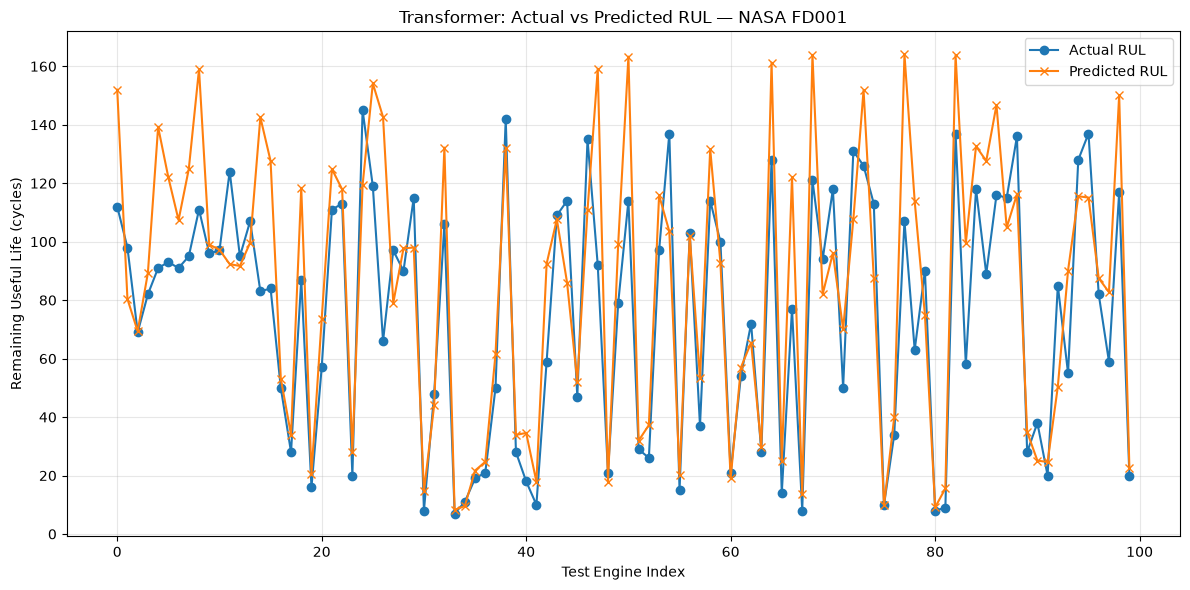

In [67]:

import matplotlib.pyplot as plt
import numpy as np

# Predict RUL for all 100 test engines
transformer_model.eval()

with torch.no_grad():
    test_predictions = transformer_model(
        X_test_tensor
    ).cpu().numpy().flatten()

test_predictions = np.maximum(test_predictions, 0)
y_test_true = rul_df["RUL"].to_numpy()

# Plot actual vs predicted
plt.figure(figsize=(12, 6))
plt.plot(y_test_true, label="Actual RUL", marker="o")
plt.plot(test_predictions, label="Predicted RUL", marker="x")
plt.xlabel("Test Engine Index")
plt.ylabel("Remaining Useful Life (cycles)")
plt.title("Transformer: Actual vs Predicted RUL — NASA FD001")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [68]:
print("LSTM model available:", "improved_lstm" in globals())
print("XGBoost model available:", "xgb_original" in globals())
print("Transformer model available:", "transformer_model" in globals())

LSTM model available: True
XGBoost model available: True
Transformer model available: True


In [69]:

import pandas as pd
import numpy as np
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Actual official test RUL labels
y_test_true = rul_df["RUL"].to_numpy()

# 1. Transformer predictions
transformer_model.eval()
with torch.no_grad():
    transformer_preds = transformer_model(
        X_test_tensor.to(device)
    ).cpu().numpy().flatten()

transformer_preds = np.maximum(transformer_preds, 0)

# 2. LSTM predictions on the same 100 test sequences
improved_lstm.eval()
with torch.no_grad():
    lstm_preds = improved_lstm(
        X_test_tensor.to(device)
    ).cpu().numpy().flatten()

lstm_preds = np.maximum(lstm_preds, 0)

# 3. XGBoost predictions from each engine's final observed cycle
last_cycle_rows = (
    test_df.sort_values("cycle")
    .groupby("engine_id", sort=True)
    .tail(1)
    .sort_values("engine_id")
)

X_test_last = last_cycle_rows[feature_columns]
xgb_preds = np.maximum(
    xgb_original.predict(X_test_last),
    0
)

# Compare all models using identical test engines and labels
results = []

for name, preds in [
    ("XGBoost", xgb_preds),
    ("LSTM", lstm_preds),
    ("Transformer", transformer_preds)
]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_true, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test_true, preds)),
        "R2": r2_score(y_test_true, preds)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
print(results_df.round(4).to_string(index=False))


      Model     MAE    RMSE     R2
       LSTM 17.6053 24.0977 0.6637
Transformer 18.8980 25.2003 0.6322
    XGBoost 24.3677 34.1241 0.3257


In [70]:

from pathlib import Path
import joblib
import json
import torch

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save LSTM weights
torch.save(
    improved_lstm.state_dict(),
    model_dir / "lstm_fd001.pth"
)

# Save preprocessing scaler
joblib.dump(
    scaler,
    model_dir / "scaler_fd001.joblib"
)

# Save model configuration
config = {
    "model": "ImprovedRULLSTM",
    "dataset": "NASA C-MAPSS FD001",
    "input_features": feature_columns,
    "sequence_length": SEQUENCE_LENGTH,
    "input_size": len(feature_columns),
    "target": "uncapped RUL",
    "test_mae": 17.6053,
    "test_rmse": 24.0977,
    "test_r2": 0.6637
}

with open(model_dir / "lstm_fd001_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("LSTM model and preprocessing files saved successfully.")
print("Location:", model_dir.resolve())


LSTM model and preprocessing files saved successfully.
Location: models


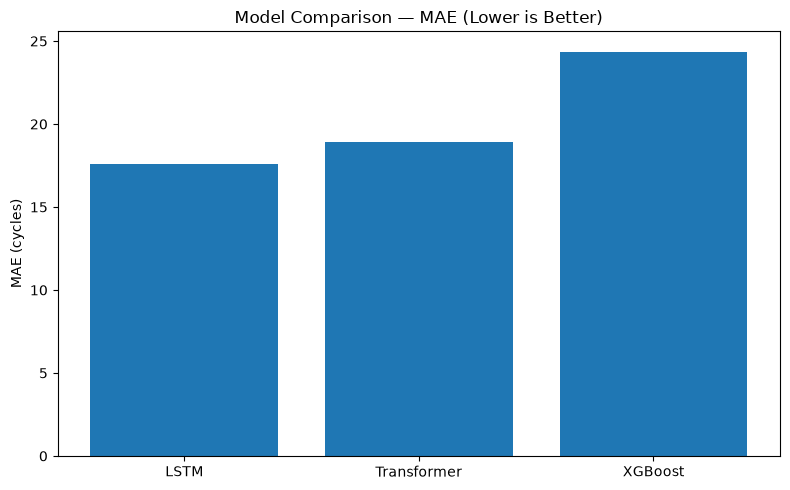

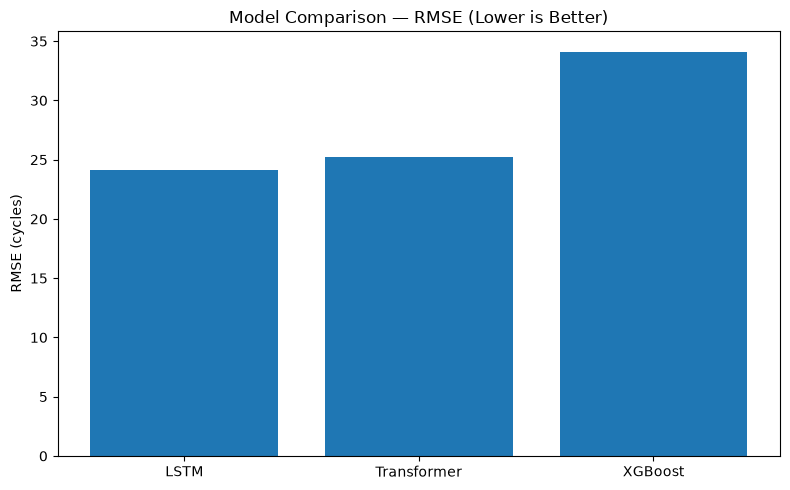

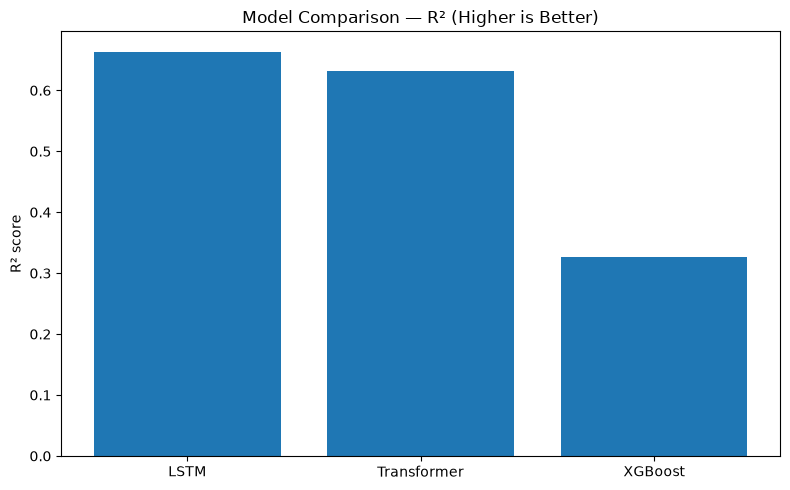

In [71]:

import matplotlib.pyplot as plt
import numpy as np

# Results from the official FD001 test set
models = ["LSTM", "Transformer", "XGBoost"]
mae_values = [17.6053, 18.8980, 24.3677]
rmse_values = [24.0977, 25.2003, 34.1241]
r2_values = [0.6637, 0.6322, 0.3257]

# Plot MAE
plt.figure(figsize=(8, 5))
plt.bar(models, mae_values)
plt.title("Model Comparison — MAE (Lower is Better)")
plt.ylabel("MAE (cycles)")
plt.tight_layout()
plt.show()

# Plot RMSE
plt.figure(figsize=(8, 5))
plt.bar(models, rmse_values)
plt.title("Model Comparison — RMSE (Lower is Better)")
plt.ylabel("RMSE (cycles)")
plt.tight_layout()
plt.show()

# Plot R²
plt.figure(figsize=(8, 5))
plt.bar(models, r2_values)
plt.title("Model Comparison — R² (Higher is Better)")
plt.ylabel("R² score")
plt.tight_layout()
plt.show()
